# Hidden communication, predictive beliefs, and useful coordination

**A runnable teaching experiment for Sandy's transducer project.** First prove a small separation using exact probabilities. Then ask whether a transformer represents the same information.

**Question:** Can a hidden relationship matter for predicting public behavior while being unnecessary for one coordination task, yet necessary for another?

This notebook constructs such a case. It does **not** prove a universal increase in complexity, establish minimal causal-state dimension, or claim a new result relative to the literature. The reward contrast is deliberately engineered. Neither a training run nor a PCA curve alone establishes a research contribution.

**Colab:** Upload this `.ipynb` using **File → Upload notebook**, choose a GPU if available, and run all cells. Sections 1–5 require no neural training. The neural section defaults to a small **pilot**; choose `smoke` to test execution or `study` for three seeds. Any saved smoke outputs only verify execution, not scientific convergence.

**Deliverable for an advisor:** an explicit generator, two interfaces, an exact filtering check, a strategic-equivalence example, a transformer baseline, and a list of limitations.


**Included run:** all code cells executed locally with `pilot`: 500 training steps per interface, 1 seed(s), cpu. These are exploratory outputs, not a converged or replicated study. Colab execution itself has not been tested.


## 1. Connect the four papers

| Paper | Object used here |
|---|---|
| [AI in a Vat](https://arxiv.org/abs/2504.04608) | A predictive world model relative to a specified observation interface |
| [From Monoliths to Modules](https://arxiv.org/abs/2512.02193) | Two components connected by an explicit message channel |
| [Transformers learn factored representations](https://arxiv.org/html/2602.02385v1) | Belief probes, residual-stream CEV, and joint-versus-marginal representations |
| [Who Needs to Know?](https://arxiv.org/html/2306.09309) | Co-player policies grouped by identical best-response sets |

The bridge is a **proposed analysis**: measure predictive loss and decision regret separately when joint information is discarded. Strategic equivalence groups policies; causal states group histories. They are not interchangeable.


In [1]:
# Standard Colab already provides these packages. Install only if missing.
import importlib.util, subprocess, sys
needed = [p for p in ['numpy', 'matplotlib', 'torch'] if importlib.util.find_spec(p) is None]
if needed:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *needed])
import os, json, copy, math, time, random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
print('Python:', sys.version.split()[0], '| NumPy:', np.__version__, '| Torch:', torch.__version__)


Python: 3.12.5 | NumPy: 2.3.1 | Torch: 2.14.0


## 2. Specify the generator completely

Sender hidden state $R_t\in\{0,1\}$ and receiver hidden state $S_t\in\{0,1\}$ evolve independently using the transition matrices below. The sender transmits the one-bit message $Y_t=R_t$. The receiver combines that message with its own state to emit a noisy parity observation.

Public outputs at each step:

- $C_t\sim\mathrm{Bernoulli}(q)$: a coordination convention signal, independent across time and of the states.
- $U_t=R_t\oplus N^U_t$: a noisy sender observation.
- $Z_t=R_t\oplus S_t\oplus N^Z_t$: a noisy receiver observation using the message.

The public symbol is $(C_t,U_t,Z_t)$, encoded as `4*C + 2*U + Z` (8 symbols).

**Visible interface:** observe $(C_t,U_t,Z_t,Y_t)$.

**Hidden interface:** observe $(C_t,U_t,Z_t)$; the message slot is masked.

The generator, sampled trajectories and public prediction target are identical across the two interfaces. The message changes the receiver's output, not its state transition. This is a simple feedforward communication construction, not learned or adaptive agents.

Timing: transition to $(R_t,S_t)$, emit the current symbol, update the belief, predict the next public symbol. Every sampled sequence begins with the stationary prior, so the exact filter and transformer see the same finite history. This is a **fixed one-bit channel**, not a channel-size sweep.


In [2]:
TR = np.array([[.90, .10], [.20, .80]])
TS = np.array([[.85, .15], [.10, .90]])
T = np.kron(TR, TS)  # state order: 00, 01, 10, 11
STATES = np.array([[0,0], [0,1], [1,0], [1,1]])
PARITY = STATES[:,0] ^ STATES[:,1]
Q = .8
EPS_U = .30
EPS_Z = .10

def stationary_binary(P):
    p1 = P[0,1] / (P[0,1] + P[1,0])
    return np.array([1-p1, p1])

PRIOR = np.outer(stationary_binary(TR), stationary_binary(TS)).ravel()
PUBLIC = np.array([[c,u,z] for c in range(2) for u in range(2) for z in range(2)])

def emission_matrix(q=Q, eps_u=EPS_U, eps_z=EPS_Z):
    c, u, z = PUBLIC.T
    return (np.where(c[None,:] == 1, q, 1-q)
            * np.where(STATES[:,0,None] == u[None,:], 1-eps_u, eps_u)
            * np.where(PARITY[:,None] == z[None,:], 1-eps_z, eps_z))

E = emission_matrix()
assert np.allclose(T.sum(1), 1) and np.allclose(E.sum(1), 1)
assert np.allclose(PRIOR @ T, PRIOR)
print('Joint stationary prior:', PRIOR)
print('Public symbol order:', PUBLIC.tolist())


Joint stationary prior: [0.26666667 0.4        0.13333333 0.2       ]
Public symbol order: [[0, 0, 0], [0, 0, 1], [0, 1, 0], [0, 1, 1], [1, 0, 0], [1, 0, 1], [1, 1, 0], [1, 1, 1]]


## 3. Exact filtering and a matched-marginal ablation

For a current public observation $o_t$, the hidden-interface filter is

$$b_t \propto (b_{t-1}T)\odot P(o_t\mid R_t,S_t).$$

For the visible interface, multiply this likelihood by $\mathbf{1}[R_t=Y_t]$ before normalizing. Knowing $R_t$ exactly makes the current joint belief factorize (one factor is a point mass). Without $Y_t$, the parity observation can couple uncertainty over $R_t$ and $S_t$.

To discard only the current association, replace $b_t(r,s)$ with $\tilde b_t(r,s)=b_t(r)b_t(s)$. This is an **oracle one-step ablation**: it keeps exact marginals, but is not a separately implemented recursive approximate filter.

**Two one-step decision tasks:** after an observation prefix, choose a binary action. The convention task pays $1[a=C_{t+1}]$; the parity task pays $1[a=R_{t+1}\oplus S_{t+1}]$. We score these decisions offline. Rewards are not fed back into the observation history, so this is not a sequential RL experiment. Revealing parity rewards during an episode would change the information available and require a new filter.

Every conditional probability below is calculated exactly; reported averages are Monte Carlo averages over sampled histories.

Compare next-public-symbol distributions $b_tTE$ and $\tilde b_tTE$, and next-latent-parity probabilities $b_tT\,\mathrm{PARITY}$ and $\tilde b_tT\,\mathrm{PARITY}$. A decoder based only on marginals could sometimes infer extra structure from the restricted reachable set; this product ablation does not rule that out.


In [3]:
def sample_sequences(n, length, seed, q=Q, eps_z=EPS_Z):
    rng = np.random.default_rng(seed)
    r = rng.choice(2, n, p=stationary_binary(TR))
    s = rng.choice(2, n, p=stationary_binary(TS))
    pub, message, latent = [], [], []
    for t in range(length):
        r = (rng.random(n) < TR[r,1]).astype(int)
        s = (rng.random(n) < TS[s,1]).astype(int)
        c = (rng.random(n) < q).astype(int)
        u = r ^ (rng.random(n) < EPS_U)
        z = r ^ s ^ (rng.random(n) < eps_z)
        pub.append(4*c + 2*u + z)
        message.append(r.copy())
        latent.append(2*r+s)
    return {'public': np.stack(pub,1), 'message': np.stack(message,1),
            'latent': np.stack(latent,1)}

def filter_sequences(data, visible, q=Q, eps_z=EPS_Z):
    em = emission_matrix(q=q, eps_z=eps_z)
    n, length = data['public'].shape
    b = np.tile(PRIOR, (n,1)); history = []
    for t in range(length):
        b = (b @ T) * em[:, data['public'][:,t]].T
        if visible:
            b *= STATES[None,:,0] == data['message'][:,t,None]
        norm = b.sum(1,keepdims=True)
        assert np.all(norm > 0)
        b = b / norm
        history.append(b.copy())
    return np.stack(history,1)

def product_of_marginals(b):
    table = b.reshape(*b.shape[:-1],2,2)
    r, s = table.sum(-1), table.sum(-2)
    return (r[..., :,None] * s[..., None,:]).reshape(b.shape)

def association(b):
    table = b.reshape(*b.shape[:-1],2,2)
    return b[...,3] - table.sum(-1)[...,1]*table.sum(-2)[...,1]

def belief_information(b):
    bp = product_of_marginals(b)
    return np.sum(b*np.log(np.clip(b,1e-15,1)/np.clip(bp,1e-15,1)), axis=-1)

def kl(p, q):
    return np.sum(p*np.log(np.clip(p,1e-15,1)/np.clip(q,1e-15,1)),axis=-1)

def binary_regret(p_true, p_used):
    # Expected regret under the exact conditional distribution, tie -> action 1.
    chosen_reward = np.where(p_used >= .5, p_true, 1-p_true)
    return np.maximum(p_true, 1-p_true) - chosen_reward

DATA = sample_sequences(2048, 33, seed=11)
BELIEFS = {name: filter_sequences(DATA, name == 'visible')
           for name in ['visible','hidden']}
EXACT = {}
for name, all_b in BELIEFS.items():
    b = all_b[:,:-1]; bp = product_of_marginals(b)
    pred, pred_product = b @ T @ E, bp @ T @ E
    p, p_product = b @ T @ PARITY, bp @ T @ PARITY
    EXACT[name] = {
        'mean posterior dependence (nats)': float(belief_information(b).mean()),
        'public prediction KL after ablation (nats)': float(kl(pred,pred_product).mean()),
        'convention-task regret': 0.0,  # Exact: both representations imply P(C_next=1)=q.
        'parity-task regret': float(binary_regret(p,p_product).mean()),
        'fraction parity decisions changed': float(((p>=.5)!=(p_product>=.5)).mean())}
print(json.dumps(EXACT, indent=2))
assert np.max(np.abs(association(BELIEFS['visible']))) < 1e-12
assert EXACT['hidden']['public prediction KL after ablation (nats)'] > 1e-4
assert EXACT['hidden']['parity-task regret'] > 1e-4


{
  "visible": {
    "mean posterior dependence (nats)": 3.1620698705744564e-17,
    "public prediction KL after ablation (nats)": 2.216497943514591e-17,
    "convention-task regret": 0.0,
    "parity-task regret": 0.0,
    "fraction parity decisions changed": 0.0
  },
  "hidden": {
    "mean posterior dependence (nats)": 0.2506782064325621,
    "public prediction KL after ablation (nats)": 0.027258907146520135,
    "convention-task regret": 0.0,
    "parity-task regret": 0.03902535807859798,
    "fraction parity decisions changed": 0.1364898681640625
  }
}


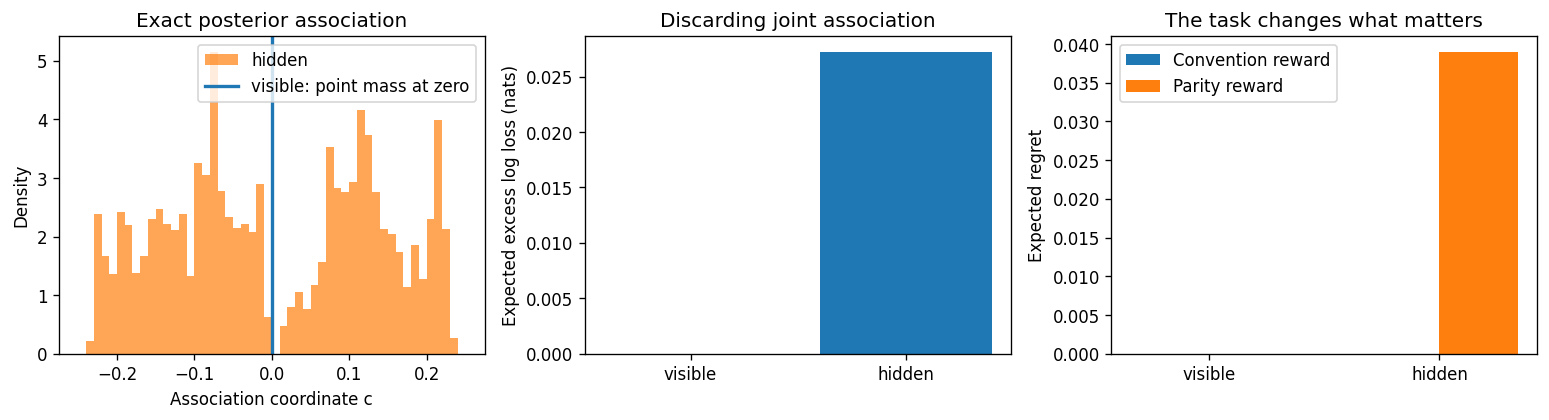

In [4]:
fig, axes = plt.subplots(1,3,figsize=(13,3.6))
axes[0].hist(association(BELIEFS['hidden']).ravel(),bins=np.linspace(-.25,.25,51),
             alpha=.7,density=True,color='tab:orange',label='hidden')
axes[0].axvline(0,color='tab:blue',lw=2,label='visible: point mass at zero')
axes[0].set(xlabel='Association coordinate c',ylabel='Density',title='Exact posterior association')
axes[0].legend()
names = ['visible','hidden']
axes[1].bar(names,[EXACT[n]['public prediction KL after ablation (nats)'] for n in names])
axes[1].set(ylabel='Expected excess log loss (nats)',title='Discarding joint association')
x=np.arange(2)
axes[2].bar(x-.17,[EXACT[n]['convention-task regret'] for n in names],.34,label='Convention reward')
axes[2].bar(x+.17,[EXACT[n]['parity-task regret'] for n in names],.34,label='Parity reward')
axes[2].set(xticks=x,xticklabels=names,ylabel='Expected regret',title='The task changes what matters')
axes[2].legend()
plt.tight_layout(); plt.show()


## 4. An exact strategic-equivalence calculation

Treat the two-component collective as a fixed co-player. Its policy family is indexed by $(q,\epsilon_Z)$; the latent transitions stay fixed. Changing the receiver's emission randomization changes public behavior. The focal agent chooses $a_t\in\{0,1\}$ after observing history and receives shared reward $1[a_t=C_{t+1}]$.

Because $C_{t+1}$ is independent of history with known parameter $q$, the optimal action at every history is 1 for $q>1/2$, 0 for $q<1/2$, and either for $q=1/2$. Thus different $\epsilon_Z$ values at the same $q$ are strategically equivalent for this task even though their public predictions differ. This also extends to any finite horizon with additive reward: actions do not affect observations or transitions, so there is no information-gathering tradeoff.

We calculate best responses **to each known policy**. If $q$ or the policy identity is unknown, inference about it is a separate problem. This is a small passive coordination game, not a solution to general DecPOMDP planning.


In [5]:
def convention_br(q):
    if np.isclose(q,.5): return (0,1)
    return (int(q>.5),)

classes = {}
for q in [.2,.8]:
    for ez in [.05,.25]:
        policy = (q,ez)
        classes.setdefault(convention_br(q),[]).append(policy)
        print(f'policy(q={q}, eps_z={ez}): BR={convention_br(q)}, value={max(q,1-q):.3f}')
print('Strategic equivalence classes:', classes)
p_low = PRIOR @ emission_matrix(q=.8,eps_z=.05)
p_high = PRIOR @ emission_matrix(q=.8,eps_z=.25)
print('One-step predictive total variation within one strategic class:', .5*np.abs(p_low-p_high).sum())
assert not np.allclose(p_low,p_high)
assert convention_br(.8) == (1,)

# Verify that exact and product beliefs agree on next convention predictions.
for b in BELIEFS.values():
    public_next = b @ T @ E
    assert np.allclose(public_next[...,PUBLIC[:,0] == 1].sum(-1), Q)


policy(q=0.2, eps_z=0.05): BR=(0,), value=0.800
policy(q=0.2, eps_z=0.25): BR=(0,), value=0.800
policy(q=0.8, eps_z=0.05): BR=(1,), value=0.800
policy(q=0.8, eps_z=0.25): BR=(1,), value=0.800
Strategic equivalence classes: {(0,): [(0.2, 0.05), (0.2, 0.25)], (1,): [(0.8, 0.05), (0.8, 0.25)]}
One-step predictive total variation within one strategic class: 0.016000000000000025


## 5. Checks that make the example trustworthy

These tests check normalization, agreement with brute-force state-path enumeration for a short sequence, visible-interface factorization, and the static same-marginals/different-parity example. They do not establish minimality of the dynamic belief representation.


In [6]:
from itertools import product

def brute_posterior(public, messages=None):
    # States here are the post-transition emitting states; stationary initial law.
    result = np.zeros(4)
    for path in product(range(4), repeat=len(public)):
        weight = PRIOR[path[0]]
        for t, state in enumerate(path):
            if t: weight *= T[path[t-1],state]
            weight *= E[state,public[t]]
            if messages is not None:
                weight *= int(STATES[state,0] == messages[t])
        result[path[-1]] += weight
    return result/result.sum()

for visible in [False,True]:
    small = {k:v[:1,:3] for k,v in DATA.items()}
    exact = filter_sequences(small,visible)[0,-1]
    brute = brute_posterior(small['public'][0],small['message'][0] if visible else None)
    assert np.allclose(exact,brute,atol=1e-12)
for b in BELIEFS.values():
    assert np.allclose(b.sum(-1),1) and b.min() >= 0
same = np.array([.5,0,0,.5]); different = np.array([0,.5,.5,0])
assert np.allclose(product_of_marginals(same),product_of_marginals(different))
assert same @ PARITY == 0 and different @ PARITY == 1
print('All exact-model checks passed.')


All exact-model checks passed.


## 6. Optional transformer experiment

**Hypothesis to test, not a guaranteed outcome:** learned activations contain the joint information needed to predict the public process. We do not assume hidden activations have higher PCA dimension. Revealing a variable also adds input information, and PCA depends on coordinates, token identity and training quality.

We train one model per interface with the same architecture, paired initial weights and paired generated batches. Both predict the **next public symbol**. Message information is an input feature at each current position, not an additional prediction target. There are 24 possible input IDs: 8 public symbols times message slot {0,1,masked}. This controls sequence length and public target vocabulary, but does not eliminate input-identity confounds.

`pilot` is an exploratory single seed. `study` uses three seeds, but convergence, capacity and context-length checks remain necessary. Report loss above each interface's own Bayes baseline; raw losses need not be equal.


In [7]:
PROFILE = os.environ.get('TRANSDUCER_PROFILE', 'pilot')  # 'smoke', 'pilot', 'study'
RUN_TRAINING = True  # Set False to stop at exact results.
PROFILES = {
 'smoke': dict(steps=8,batch=16,length=12,width=32,layers=1,eval_n=64,seeds=[0]),
 'pilot': dict(steps=500,batch=64,length=32,width=64,layers=2,eval_n=512,seeds=[0]),
 'study': dict(steps=2000,batch=64,length=32,width=64,layers=2,eval_n=1024,seeds=[0,1,2])}
CFG=PROFILES[PROFILE]
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cpu': torch.set_num_threads(min(4,os.cpu_count() or 1))
print('Profile:', PROFILE, '| device:', DEVICE, '| config:', CFG)
print('Smoke runs validate execution only. No convergence claim is made.')

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def model_inputs(data,visible):
    slot = data['message'] if visible else np.full_like(data['message'],2)
    return data['public'] + 8*slot

class Predictor(nn.Module):
    def __init__(self,width,layers,length):
        super().__init__()
        self.token=nn.Embedding(24,width)
        self.position=nn.Embedding(length,width)
        self.blocks=nn.ModuleList([
            nn.TransformerEncoderLayer(width,4,dim_feedforward=4*width,
                dropout=0,batch_first=True,norm_first=True,activation='gelu')
            for _ in range(layers)])
        self.norm=nn.LayerNorm(width); self.head=nn.Linear(width,8)
    def forward(self,x,return_acts=False):
        h=self.token(x)+self.position(torch.arange(x.shape[1],device=x.device))[None]
        acts=[h]
        mask=torch.triu(torch.ones(x.shape[1],x.shape[1],device=x.device,dtype=torch.bool),diagonal=1)
        for block in self.blocks:
            h=block(h,src_mask=mask); acts.append(h)
        logits=self.head(self.norm(h))
        return (logits,acts) if return_acts else logits

# Verify causality: modifying later tokens cannot change earlier outputs.
set_seed(99)
check=Predictor(CFG['width'],CFG['layers'],CFG['length']).eval()
x=torch.randint(24,(2,CFG['length'])); x2=x.clone(); cut=CFG['length']//2
x2[:,cut:]=(x2[:,cut:]+1)%24
with torch.no_grad():
    assert torch.allclose(check(x)[:,:cut],check(x2)[:,:cut],atol=1e-6)
del check
print('Causal-attention check passed.')


Profile: pilot | device: cpu | config: {'steps': 500, 'batch': 64, 'length': 32, 'width': 64, 'layers': 2, 'eval_n': 512, 'seeds': [0]}
Smoke runs validate execution only. No convergence claim is made.
Causal-attention check passed.


In [8]:
MODELS={}; TRAINING={}
if RUN_TRAINING:
    for seed in CFG['seeds']:
        for name in ['visible','hidden']:
            set_seed(seed)
            model=Predictor(CFG['width'],CFG['layers'],CFG['length']).to(DEVICE)
            optimizer=torch.optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4)
            records=[]; start=time.time(); model.train()
            for step in range(CFG['steps']):
                # Identical generated trajectories across interfaces for each seed/step.
                data=sample_sequences(CFG['batch'],CFG['length']+1,
                                      seed=100000+seed*10000+step)
                inputs=torch.as_tensor(model_inputs(data,name=='visible')[:,:-1],device=DEVICE)
                targets=torch.as_tensor(data['public'][:,1:],device=DEVICE)
                optimizer.zero_grad(set_to_none=True)
                logits=model(inputs)
                loss=F.cross_entropy(logits.reshape(-1,8),targets.reshape(-1))
                loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.)
                optimizer.step()
                if step==0 or (step+1)%max(1,CFG['steps']//10)==0:
                    records.append((step+1,float(loss.detach())))
            MODELS[(seed,name)]=model.eval(); TRAINING[(seed,name)]=records
            print(f'{name}, seed {seed}: {CFG["steps"]} steps, {time.time()-start:.1f}s, last train CE={records[-1][1]:.4f}')
else:
    print('Training skipped; exact results remain available.')


visible, seed 0: 500 steps, 3.2s, last train CE=1.7564
hidden, seed 0: 500 steps, 3.1s, last train CE=1.7970


## 7. Held-out prediction and layerwise belief probes

Probe training and evaluation use separate complete sequences. Ridge regression predicts **all four joint probabilities** from each layer; we report raw probe MSE and its association error. For decision calculations only, project decoded beliefs to the probability simplex, and report the size of that repair. Repair can improve feasibility but does not make a bad probe accurate.

We also fit a baseline from the exact two marginal probabilities to the true joint belief. Its held-out error tests whether a *linear* map from marginals suffices on this sampled distribution; it is not a test of all nonlinear reconstructions.

Probe-derived parity regret describes a downstream decision using decoded beliefs. It is **not** evidence the network causally uses those coordinates. Later activation interventions would be a separate experiment.


In [9]:
def ridge_fit(x,y,alpha=1e-3):
    # Standardized feature ridge; intercept unpenalized; fit on probe-training set only.
    xm=x.mean(0); xs=x.std(0); xs=np.where(xs<1e-8,1.,xs); ym=y.mean(0)
    z=(x-xm)/xs
    w=np.linalg.solve(z.T@z/len(z)+alpha*np.eye(z.shape[1]),z.T@(y-ym)/len(z))
    return xm,xs,ym,w

def ridge_predict(fit,x):
    xm,xs,ym,w=fit
    return (x-xm)/xs@w+ym

def simplex_project(v):
    # Euclidean projection onto nonnegative vectors summing to 1.
    u=np.sort(v,axis=1)[:,::-1]; css=np.cumsum(u,axis=1)-1
    j=np.arange(1,v.shape[1]+1)
    rho=(u-css/j>0).sum(1)-1
    theta=css[np.arange(len(v)),rho]/(rho+1)
    return np.maximum(v-theta[:,None],0)

def marginal_features(b):
    m=b.reshape(-1,2,2)
    return np.column_stack([m.sum(2)[:,1],m.sum(1)[:,1]])

@torch.no_grad()
def collect(model,data,visible,batch=64):
    xs=model_inputs(data,visible)[:,:-1]; logits_out=[]; layer_out=None
    for start in range(0,len(xs),batch):
        logits, acts=model(torch.as_tensor(xs[start:start+batch],device=DEVICE),True)
        logits_out.append(logits.cpu().numpy())
        if layer_out is None: layer_out=[[] for _ in acts]
        for j,a in enumerate(acts): layer_out[j].append(a.cpu().numpy())
    return np.concatenate(logits_out),[np.concatenate(v) for v in layer_out]

RESULTS=[]; PROBES=[]; GEOMETRY={}
if RUN_TRAINING:
    for seed in CFG['seeds']:
        train_data=sample_sequences(CFG['eval_n'],CFG['length']+1,800000+seed)
        test_data=sample_sequences(CFG['eval_n'],CFG['length']+1,900000+seed)
        for name in ['visible','hidden']:
            visible=name=='visible'; model=MODELS[(seed,name)]
            _, a_train=collect(model,train_data,visible)
            logits,a_test=collect(model,test_data,visible)
            bt=filter_sequences(train_data,visible)[:,:-1].reshape(-1,4)
            be=filter_sequences(test_data,visible)[:,:-1].reshape(-1,4)
            true_pred=be@T@E
            raw=logits.reshape(-1,8).astype(float); raw-=raw.max(1,keepdims=True)
            pred=np.exp(raw);pred/=pred.sum(1,keepdims=True)
            y=test_data['public'][:,1:].ravel(); idx=np.arange(len(y))
            RESULTS.append(dict(seed=seed,interface=name,
                test_CE=float(-np.log(np.clip(pred[idx,y],1e-15,1)).mean()),
                sampled_Bayes_CE=float(-np.log(true_pred[idx,y]).mean()),
                expected_excess_CE_KL=float(kl(true_pred,pred).mean()),
                convention_regret=float(binary_regret(np.full(len(y),Q),pred[:,PUBLIC[:,0]==1].sum(1)).mean())))
            base=ridge_predict(ridge_fit(marginal_features(bt),bt),marginal_features(be))
            print(f'{name}, seed {seed}: marginal-only linear baseline joint MSE={np.mean((base-be)**2):.6f}')
            for layer,(atr,ate) in enumerate(zip(a_train,a_test)):
                xtr=atr.reshape(-1,atr.shape[-1]).astype(float)
                xte=ate.reshape(-1,ate.shape[-1]).astype(float)
                decoded=ridge_predict(ridge_fit(xtr,bt),xte)
                valid=simplex_project(decoded)
                PROBES.append(dict(seed=seed,interface=name,layer=layer,
                    joint_MSE=float(np.mean((decoded-be)**2)),
                    association_MSE=float(np.mean((association(valid)-association(be))**2)),
                    simplex_repair_RMS=float(np.sqrt(np.mean((decoded-valid)**2))),
                    decoded_parity_regret=float(binary_regret(be@T@PARITY,valid@T@PARITY).mean())))
                GEOMETRY[(seed,name,layer)]=dict(train=xtr,test=xte,belief=be,
                    train_data=train_data,test_data=test_data)
    print('Held-out prediction metrics:'); print(json.dumps(RESULTS,indent=2))
    print('Belief probe metrics (layer 0 is the input embedding):'); print(json.dumps(PROBES,indent=2))


visible, seed 0: marginal-only linear baseline joint MSE=0.037409
hidden, seed 0: marginal-only linear baseline joint MSE=0.025205
Held-out prediction metrics:
[
  {
    "seed": 0,
    "interface": "visible",
    "test_CE": 1.7651208688191886,
    "sampled_Bayes_CE": 1.7570239015913347,
    "expected_excess_CE_KL": 0.008710818568650733,
    "convention_regret": 0.0
  },
  {
    "seed": 0,
    "interface": "hidden",
    "test_CE": 1.7994020238994723,
    "sampled_Bayes_CE": 1.7920481245618456,
    "expected_excess_CE_KL": 0.006606663670799808,
    "convention_regret": 0.0
  }
]
Belief probe metrics (layer 0 is the input embedding):
[
  {
    "seed": 0,
    "interface": "visible",
    "layer": 0,
    "joint_MSE": 0.009544455551872708,
    "association_MSE": 4.272728982652048e-06,
    "simplex_repair_RMS": 0.0024484308459760762,
    "decoded_parity_regret": 0.0003653852817779376
  },
  {
    "seed": 0,
    "interface": "visible",
    "layer": 1,
    "joint_MSE": 0.006403347427160842,
    

## 8. CEV with a token/position control

Center activations and sort singular values descending. $\mathrm{CEV}(k)=\sum_{i\le k}\sigma_i^2/\sum_i\sigma_i^2$. Report $d_{90},d_{95},d_{99}$ and participation ratio. These measure linear variance, not statistical complexity or minimum predictive memory.

The second curve first subtracts a ridge fit of current input-token identity and position, learned on probe-training sequences. This is a sensitivity analysis: current tokens contain real predictive information too, so nuisance regression may remove signal. It does not certify a causal interpretation.

For fairness, plot the same residual layer and distinguish seeds. Do not pool cross-seed activations into one PCA.


visible 0 exact joint-coordinate belief d90/d95/d99: [3, 3, 3]
hidden 0 exact joint-coordinate belief d90/d95/d99: [3, 3, 3]
[
  {
    "seed": 0,
    "interface": "visible",
    "layer": 2,
    "analysis": "raw",
    "d90": 21,
    "d95": 28,
    "d99": 39,
    "participation_ratio": 7.995492903535724
  },
  {
    "seed": 0,
    "interface": "visible",
    "layer": 2,
    "analysis": "token-position residual",
    "d90": 15,
    "d95": 27,
    "d99": 50,
    "participation_ratio": 3.4108965022040962
  },
  {
    "seed": 0,
    "interface": "hidden",
    "layer": 2,
    "analysis": "raw",
    "d90": 19,
    "d95": 26,
    "d99": 36,
    "participation_ratio": 6.95689376114921
  },
  {
    "seed": 0,
    "interface": "hidden",
    "layer": 2,
    "analysis": "token-position residual",
    "d90": 11,
    "d95": 22,
    "d99": 45,
    "participation_ratio": 3.7816095256559374
  }
]


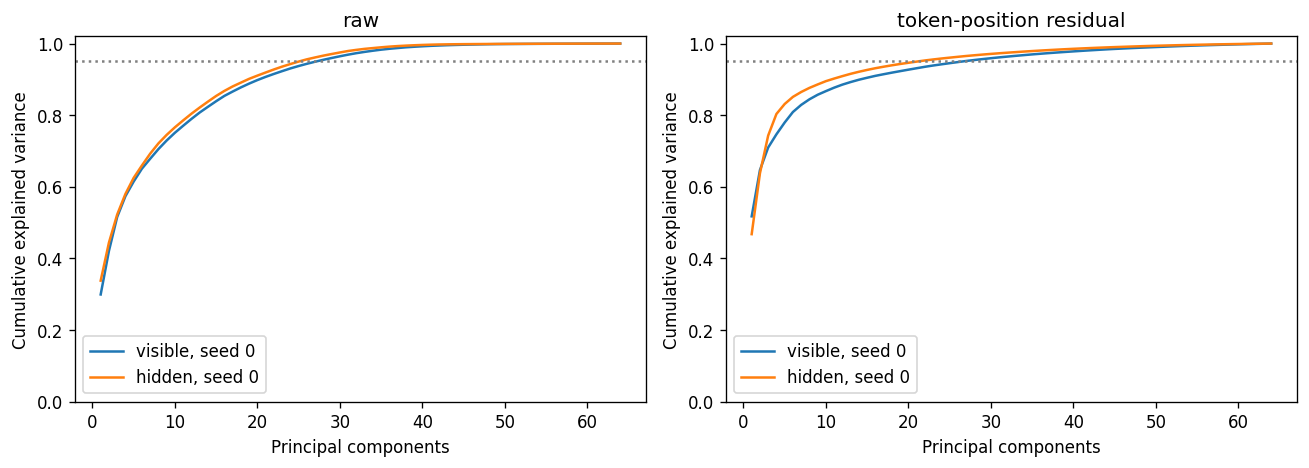

In [10]:
def cev(x):
    x=x-x.mean(0)
    variance=np.linalg.svd(x,compute_uv=False)**2
    if variance.sum()<1e-14:
        return np.zeros_like(variance),0.,[0,0,0]
    curve=np.cumsum(variance)/variance.sum()
    dims=[int(np.searchsorted(curve,p)+1) for p in [.90,.95,.99]]
    pr=float(variance.sum()**2/np.square(variance).sum())
    return curve,pr,dims

def nuisance_features(data,visible):
    ids=model_inputs(data,visible)[:,:-1]
    positions=np.broadcast_to(np.arange(ids.shape[1]),ids.shape)
    return np.concatenate([np.eye(24)[ids.ravel()],np.eye(ids.shape[1])[positions.ravel()]],axis=1)

CEV_RESULTS=[]
if RUN_TRAINING:
    layer=CFG['layers']
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for seed in CFG['seeds']:
        for name in ['visible','hidden']:
            g=GEOMETRY[(seed,name,layer)]
            ntr=nuisance_features(g['train_data'],name=='visible')
            nte=nuisance_features(g['test_data'],name=='visible')
            residual=g['test']-ridge_predict(ridge_fit(ntr,g['train']),nte)
            for ax,label,x in zip(axes,['raw','token-position residual'],[g['test'],residual]):
                curve,pr,dims=cev(x)
                ax.plot(np.arange(1,len(curve)+1),curve,label=f'{name}, seed {seed}')
                CEV_RESULTS.append(dict(seed=seed,interface=name,layer=layer,analysis=label,
                                       d90=dims[0],d95=dims[1],d99=dims[2],participation_ratio=pr))
                ax.set(title=label,xlabel='Principal components',ylabel='Cumulative explained variance',ylim=(0,1.02))
            belief_curve,belief_pr,belief_dims=cev(g['belief'])
            print(name,seed,'exact joint-coordinate belief d90/d95/d99:',belief_dims)
    for ax in axes: ax.axhline(.95,color='gray',ls=':');ax.legend()
    plt.tight_layout();plt.show()
    print(json.dumps(CEV_RESULTS,indent=2))


## 9. Save the run and interpret it

- **Exact separation:** the association ablation increases public prediction loss; its effect on coordination depends on the reward. This is a verified property of the constructed task, not learned behavior.
- **Strategic equivalence:** the four enumerated co-player policies fall into two best-response classes for the convention task. This is not a calculation of minimal causal states.
- **Neural evidence:** assess excess loss and probe errors before interpreting PCA. Low probe error is decodability, not causal use. A smoke run provides no scientific neural conclusion.
- **No guaranteed rank ordering:** visible observations can increase activation variation; product beliefs can have a curved embedding in joint coordinates. Loss of factorization does not imply a fixed PCA difference.

**Next decisions for the advisor:**

1. Is this engineered reward contrast useful, or should the task be a more natural cooperative environment?
2. Which channel intervention should follow: visibility, receiver noise, or a family with genuinely varying message alphabet size?
3. Is the intended contribution about observer prediction, strategically sufficient memory, or learned representation? Each needs a separate success criterion.

**Extensions not implemented:** full DecPOMDP best-response enumeration, unknown co-policy inference, minimal epsilon-transducer construction, proofs of nonlinear representational lower bounds, a channel-capacity law, neural causal interventions, and adaptive/RL-trained generating agents.


In [11]:
OUTPUT=Path('hidden_channel_results'); OUTPUT.mkdir(exist_ok=True)
summary={'profile':PROFILE,'config':CFG,'device':str(DEVICE),'exact':EXACT,
         'prediction':RESULTS,'probes':PROBES,'cev':CEV_RESULTS,
         'parameters':{'TR':TR.tolist(),'TS':TS.tolist(),'q':Q,'eps_u':EPS_U,'eps_z':EPS_Z},
         'versions':{'python':sys.version.split()[0],'numpy':np.__version__,'torch':torch.__version__},
         'caution':'Smoke validates execution only. No universal complexity or novelty claim.'}
(OUTPUT/'metrics.json').write_text(json.dumps(summary,indent=2))
for (seed,name),model in MODELS.items():
    torch.save({'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},
                'config':CFG,'interface':name,'seed':seed},OUTPUT/f'model_{name}_{seed}.pt')
print('Saved metrics and model checkpoints in',OUTPUT.resolve())
# Optional Colab download:
# from google.colab import files
# files.download(str(OUTPUT/'metrics.json'))


Saved metrics and model checkpoints in /Users/sandy/Documents/ChatGPT/Transducers/hidden_channel_results
